**Today's assignment**

We have been given dataset with reported motorcycle crash incidents in Colombia, with attention to geography, severity and rider characteristics. The aim is to tell a clear descriptive road-safety story rather than claim that raw crash counts measure underlying travel risk.

**Central analytical question**

Where are reported motorcycle crashes concentrated, and how does recorded severity vary across rider or location groups?

**Step-by-step analytical instructions**

1. __Inspect and validate__

Load the CSV. Confirm whether each row is a crash, person or involved vehicle. Check incident identifiers, missing severity, date parsing and duplicate rows.

2. __Prepare a small set of fields__

Standardize severity and geography. Create month or weekday from valid dates; group ages only when age is present. Preserve unknown categories rather than removing them silently.

3. __Find the story__

Count crashes by severity and geography; compare severity composition across locations or age groups; inspect temporal distribution only where timestamps permit.

4. __Design and interpret__

Choose one principal message and show it with two or three uncluttered visuals. Explain whether patterns concern crash counts or the proportion of recorded incidents with severe outcomes.

### Libraries and Data Ingestion

In [1]:
import pandas as pd
import numpy as np

In [2]:
accidents = pd.read_csv('motorcycle_accidents_colombia.csv')
accidents.head()

,id,date_of_death,gender,date_of_birth,marital status,age,age group,department of residence,municipality_code,municipality_of_residence,condition
0,1,2014-02-24T00:00:00Z,male,1943-10-30T00:00:00Z,unknown,70,70-74,Antioquia,1,Medellín,driver
1,2,2012-11-15T00:00:00Z,male,1966-04-27T00:00:00Z,married,46,45-49,Antioquia,1,Medellín,driver
2,3,2012-11-30T00:00:00Z,male,1990-04-26T00:00:00Z,single,22,20-24,Antioquia,1,Medellín,driver
3,4,2012-11-18T00:00:00Z,male,1978-07-28T00:00:00Z,married,34,30-34,Antioquia,1,Medellín,driver
4,5,2012-07-08T00:00:00Z,male,1989-11-26T00:00:00Z,unknown,22,20-24,Antioquia,1,Medellín,driver


### Quick look at the data and check

In [3]:
accidents.shape

(416, 11)

In [4]:
# Checking for duplicates
print(accidents.shape)
accidents.drop_duplicates().shape

(416, 11)


(416, 11)

In [37]:
print(f"Unique accidents: {accidents[['id']].nunique()}")

Unique accidents: id    416
dtype: int64


- The above results indicate that the dataset has no duplicated rows, a further investigation would be to check if the person record id is also not duplicated, this is done in the above cell.

In [26]:
#describe the columns that are in the dataset.
column_descriptions = {
    "id": "Dataset identifier for this person record.",
    "date_of_death": "Recorded date of death; this is not necessarily the crash date.",
    "gender": "Recorded gender category.",
    "date_of_birth": "Recorded date of birth.",
    "marital status": "Recorded marital status.",
    "age": "Recorded age in years.",
    "age group": "Age range assigned to the person, such as 20-24.",
    "department of residence": "Department where the person was recorded as residing.",
    "municipality_code": "Recorded numeric code for the municipality of residence.",
    "municipality_of_residence": "Municipality where the person was recorded as residing.",
    "condition": "Rider role/status (driver, passenger, or unknown), not injury severity.",
}

for column in accidents.columns:
    print(f"{column}: {column_descriptions[column]}")

id: Dataset identifier for this person record.
date_of_death: Recorded date of death; this is not necessarily the crash date.
gender: Recorded gender category.
date_of_birth: Recorded date of birth.
marital status: Recorded marital status.
age: Recorded age in years.
age group: Age range assigned to the person, such as 20-24.
department of residence: Department where the person was recorded as residing.
municipality_code: Recorded numeric code for the municipality of residence.
municipality_of_residence: Municipality where the person was recorded as residing.
condition: Rider role/status (driver, passenger, or unknown), not injury severity.


In [6]:
#check data types and null values
accidents.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 416 entries, 0 to 415
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   id                         416 non-null    int64 
 1   date_of_death              416 non-null    object
 2   gender                     416 non-null    object
 3   date_of_birth              411 non-null    object
 4   marital status             416 non-null    object
 5   age                        416 non-null    int64 
 6   age group                  416 non-null    object
 7   department of residence    416 non-null    object
 8   municipality_code          416 non-null    int64 
 9   municipality_of_residence  416 non-null    object
 10  condition                  416 non-null    object
dtypes: int64(3), object(8)
memory usage: 35.9+ KB


In [7]:
#Check obvious missing values in the dataset
accidents.isna().sum()

id                           0
date_of_death                0
gender                       0
date_of_birth                5
marital status               0
age                          0
age group                    0
department of residence      0
municipality_code            0
municipality_of_residence    0
condition                    0
dtype: int64

- Most variables have no missing values, except for date_of_birth, however age and age group seems to be populated. One thing worth checking is if the age and age group is not filled with NA. 

In [8]:
#formatting the date column to datetime format
accidents["date_of_death"] = pd.to_datetime(accidents["date_of_death"], errors="coerce")
accidents["date"] = accidents["date_of_death"].dt.date

In [9]:
accidents.head(2)

,id,date_of_death,gender,date_of_birth,marital status,age,age group,department of residence,municipality_code,municipality_of_residence,condition,date
0,1,2014-02-24 00:00:00+00:00,male,1943-10-30T00:00:00Z,unknown,70,70-74,Antioquia,1,Medellín,driver,2014-02-24
1,2,2012-11-15 00:00:00+00:00,male,1966-04-27T00:00:00Z,married,46,45-49,Antioquia,1,Medellín,driver,2012-11-15


In [10]:
accidents["condition"].value_counts()

condition
driver       335
passenger     60
unknown       21
Name: count, dtype: int64

In [11]:
accidents.isna().sum()

id                           0
date_of_death                0
gender                       0
date_of_birth                5
marital status               0
age                          0
age group                    0
department of residence      0
municipality_code            0
municipality_of_residence    0
condition                    0
date                         0
dtype: int64

In [12]:
valid_accidents = accidents[accidents["condition"]!= 'unknown']

In [ ]:
#Get the month name from the date_of_death column and create a new column called month_name
valid_accidents["month_name"] = valid_accidents["date_of_death"].dt.month_name()

/var/folders/20/__xz71qd12d2m02xx46kqw1r0000gn/T/ipykernel_44166/3782421075.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  valid_accidents["month_name"] = valid_accidents["date_of_death"].dt.month_name()


### Data Analysis 

In [14]:
accidents.head(2)


,id,date_of_death,gender,date_of_birth,marital status,age,age group,department of residence,municipality_code,municipality_of_residence,condition,date
0,1,2014-02-24 00:00:00+00:00,male,1943-10-30T00:00:00Z,unknown,70,70-74,Antioquia,1,Medellín,driver,2014-02-24
1,2,2012-11-15 00:00:00+00:00,male,1966-04-27T00:00:00Z,married,46,45-49,Antioquia,1,Medellín,driver,2012-11-15


### Fatality counts by place, rider role, age, and date

The CSV has no crash-severity field: `condition` contains rider roles (`driver`, `passenger`, or `unknown`), not injury severity. Geography fields describe residence, not necessarily crash location. `date_of_death` allows date-level trends only, not time-of-day or crash-time analysis. The tables and plots below show observed counts, not population-adjusted risk.

In [44]:
import matplotlib.pyplot as plt
from IPython.display import display

crashes = pd.read_csv("motorcycle_accidents_colombia.csv")
crashes["date_of_death"] = pd.to_datetime(crashes["date_of_death"], errors="coerce", utc=True)
crashes["condition"] = crashes["condition"].fillna("unknown")


print(f"Records: {len(crashes):,}")

Records: 416


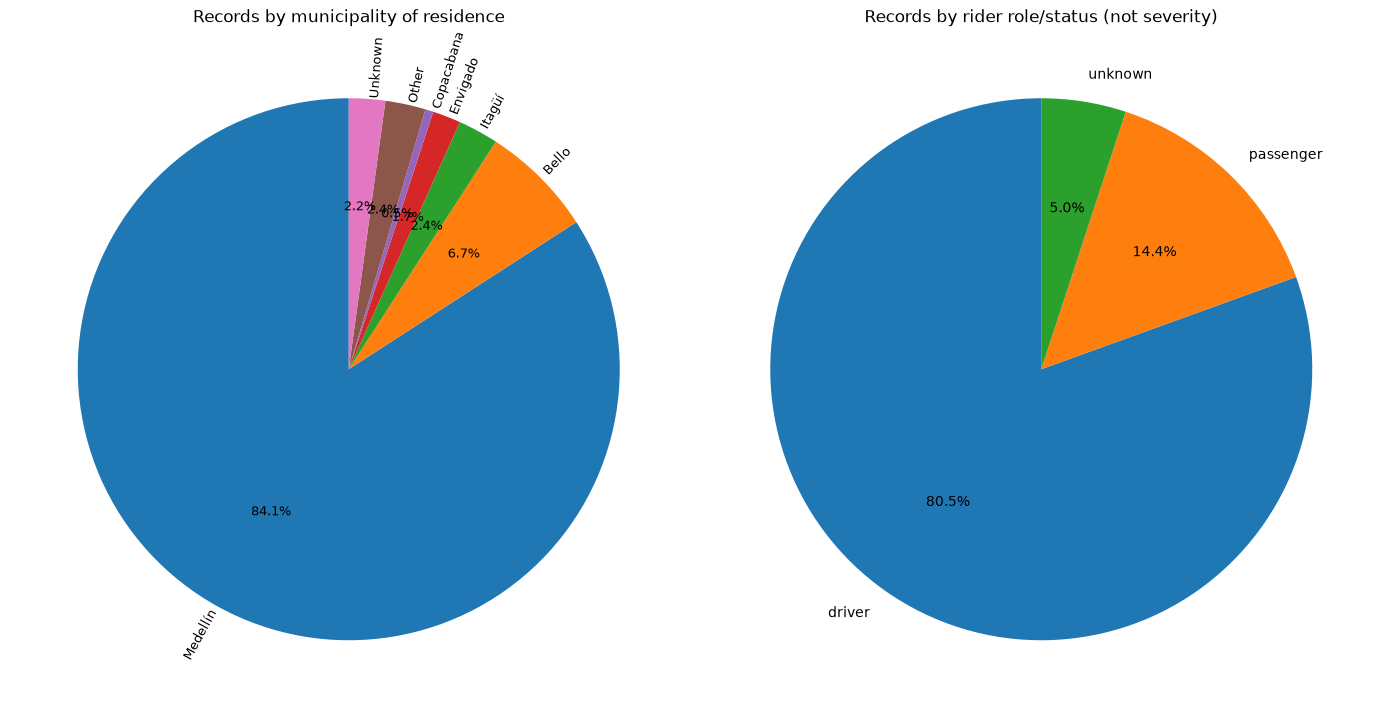

In [45]:
import matplotlib.pyplot as plt
import pandas as pd

# Municipality of residence: group smaller categories together for readability
municipalities = (
    crashes["municipality_of_residence"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

is_unknown = municipalities.str.casefold().eq("unknown")
known_counts = municipalities[~is_unknown].value_counts()
top_municipalities = known_counts.head(5)

municipality_pie = top_municipalities.copy()
other_count = known_counts.iloc[5:].sum()
unknown_count = is_unknown.sum()

if other_count:
    municipality_pie.loc["Other"] = other_count
if unknown_count:
    municipality_pie.loc["Unknown"] = unknown_count

# Rider role/status (not injury severity)
role_counts = (
    crashes["condition"]
    .fillna("unknown")
    .value_counts()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 10))

axes[0].pie(
    municipality_pie,
    labels=municipality_pie.index,
    autopct="%1.1f%%",
    startangle=90,
    rotatelabels=True,
    labeldistance=1.0,
    textprops={"fontsize": 9},
)
axes[0].set_title("Records by municipality of residence")

axes[1].pie(
    role_counts,
    labels=role_counts.index,
    autopct="%1.1f%%",
    startangle=90,
)
axes[1].set_title("Records by rider role/status (not severity)")

plt.tight_layout()
plt.show()

The above code generates two pie charts: one showing the distribution of records by municipality of residence and the other showing the distribution of records by rider role/status. The municipalities are grouped into "Other" and "Unknown" categories for better readability. 

Of the top 10 minicipalities with the most recorded deaths, Madelline has the highset records of deaths or crash incidents with 84.1% of the deaths recorded, followed by Bello at 6.7%, Drivers seem to be the ones that die more often in these accidents, in most accidents drivers end up in fatal crashes.

In [46]:

print("\nCounts by rider role/status:")
condition_counts = crashes["condition"].value_counts().rename_axis("rider role/status").to_frame("count")
display(condition_counts)


Counts by rider role/status:


,count
rider role/status,
driver,335
passenger,60
unknown,21


In [47]:
print("\nCounts by department of residence:")
department_counts = crashes["department of residence"].value_counts().rename_axis("department of residence").to_frame("count")
display(department_counts)


Counts by department of residence:


,count
department of residence,
Antioquia,405
unknown,9
Cesar,1
Atlántico,1


In [48]:
print("\nCounts by municipality of residence:")
municipality_counts = crashes["municipality_of_residence"].value_counts().rename_axis("municipality of residence").to_frame("count")
display(municipality_counts)


Counts by municipality of residence:


,count
municipality of residence,
Medellín,350
Bello,28
Itagüí,10
unknown,9
Envigado,7
Copacabana,2
Rionegro,2
Sabaneta,1
Valledupar,1


In [49]:
municipality_data = crashes[crashes["municipality_of_residence"].str.casefold() != "unknown"]
top_municipalities = municipality_data["municipality_of_residence"].value_counts().head(10).index
municipality_role_counts = pd.crosstab(
    municipality_data["municipality_of_residence"], municipality_data["condition"]
).reindex(top_municipalities)
municipality_role_percent = municipality_role_counts.div(municipality_role_counts.sum(axis=1), axis=0).mul(100)


In [50]:
age_order = sorted(
    crashes["age group"].dropna().unique(),
    key=lambda group: int(str(group).split("-")[0]) if str(group).split("-")[0].isdigit() else float("inf"),
)
age_role_counts = pd.crosstab(crashes["age group"], crashes["condition"]).reindex(age_order)
age_role_percent = age_role_counts.div(age_role_counts.sum(axis=1), axis=0).mul(100)

In [51]:
#municiplity driver/passenger counts and percentages
print("\nRider role/status counts by top 10 municipalities of residence:")
display(municipality_role_counts)
#Get the composition of rider role/status by municipality of residence as percentages
print("Composition by municipality (%):")
display(municipality_role_percent.round(1))


Rider role/status counts by top 10 municipalities of residence:


condition,driver,passenger,unknown
municipality_of_residence,,,
Medellín,278,52,20
Bello,22,5,1
Itagüí,8,2,0
Envigado,7,0,0
Copacabana,2,0,0
Rionegro,2,0,0
Sabaneta,1,0,0
Valledupar,1,0,0
La Estrella,1,0,0


Composition by municipality (%):


condition,driver,passenger,unknown
municipality_of_residence,,,
Medellín,79.4,14.9,5.7
Bello,78.6,17.9,3.6
Itagüí,80.0,20.0,0.0
Envigado,100.0,0.0,0.0
Copacabana,100.0,0.0,0.0
Rionegro,100.0,0.0,0.0
Sabaneta,100.0,0.0,0.0
Valledupar,100.0,0.0,0.0
La Estrella,100.0,0.0,0.0


In [52]:
print("\nRider role/status counts by age group:")
display(age_role_counts)
print("Composition by age group (%):")
display(age_role_percent.round(1))



Rider role/status counts by age group:


condition,driver,passenger,unknown
age group,,,
15-19,38,14,6
20-24,78,16,8
25-29,67,3,1
30-34,60,7,1
35-39,31,6,3
40-44,27,4,0
45-49,18,5,1
50-54,7,1,1
55-59,2,2,0


Composition by age group (%):


condition,driver,passenger,unknown
age group,,,
15-19,65.5,24.1,10.3
20-24,76.5,15.7,7.8
25-29,94.4,4.2,1.4
30-34,88.2,10.3,1.5
35-39,77.5,15.0,7.5
40-44,87.1,12.9,0.0
45-49,75.0,20.8,4.2
50-54,77.8,11.1,11.1
55-59,50.0,50.0,0.0


In [53]:
year_counts = crashes["date_of_death"].dropna().dt.year.value_counts().sort_index()
monthly_counts = (
    crashes.dropna(subset=["date_of_death"])
    .assign(month=lambda frame: frame["date_of_death"].dt.strftime("%Y-%m"))
    .groupby("month")
    .size()
)


What these tables reveal:
- Residence geography: Medellín is the most common known municipality (350 of 407 records with known municipality, 86.0%). Antioquia is the most common department of residence (405 of 416, 97.4%).
- Rider profile: age 20-24 is the largest group (102 of 416, 24.5%); it includes 78 drivers, 16 passengers, and 8 unknown. Overall, 335 records (80.5%) are listed as drivers.
- Timing: 2013 has the most records by date of death (112). These are death dates, not crash dates.

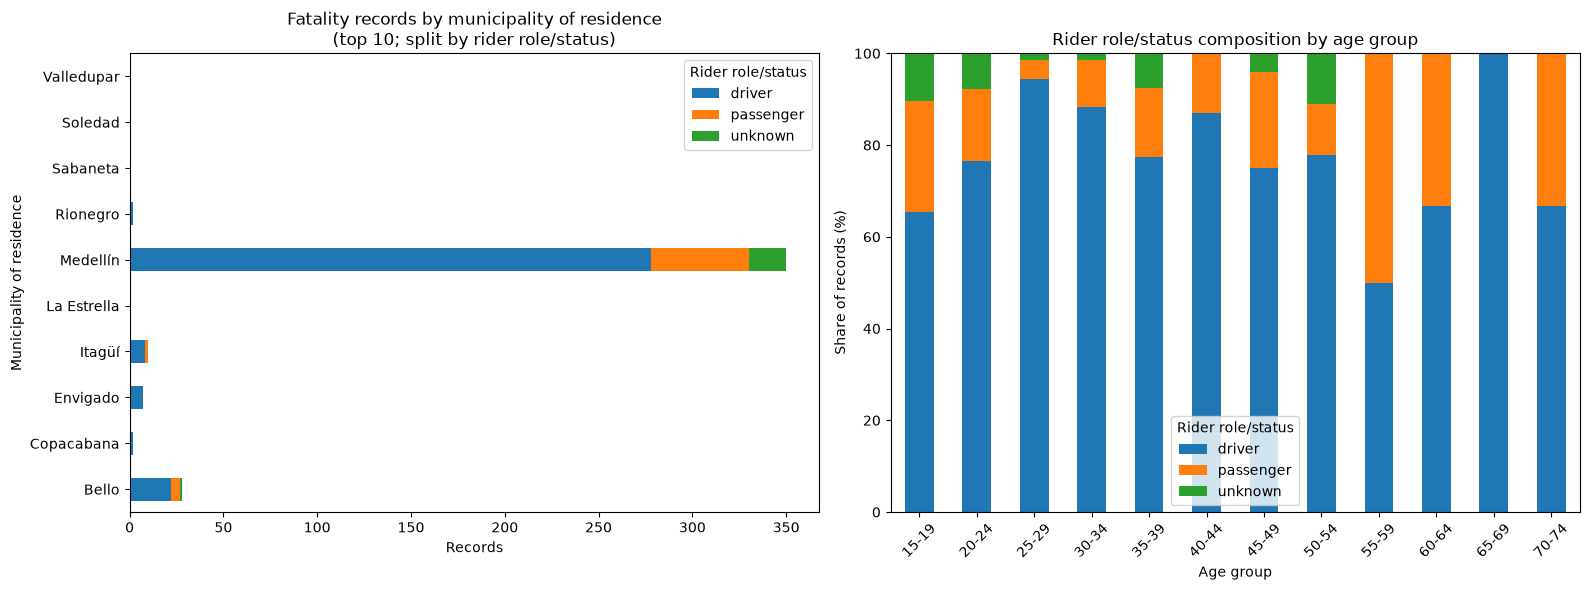

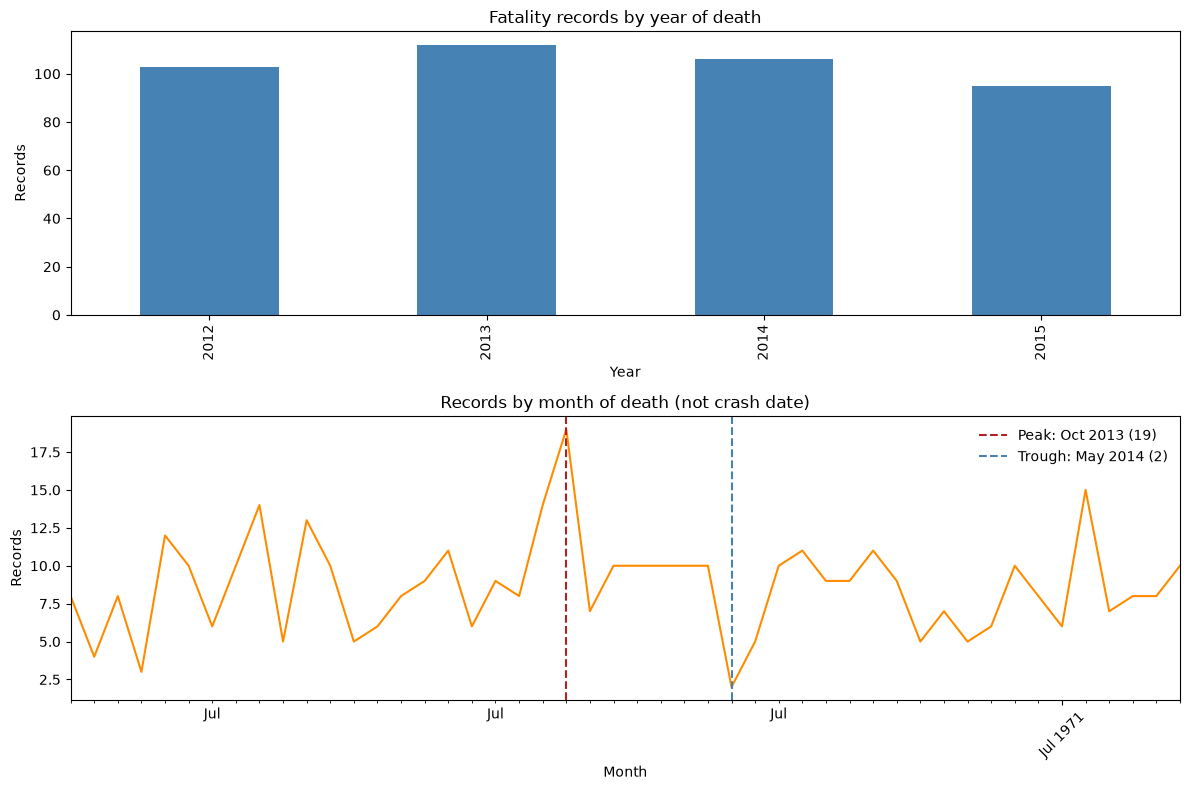

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

municipality_role_counts.sort_index().plot(kind="barh", stacked=True, ax=axes[0])
axes[0].set_title("Fatality records by municipality of residence\n(top 10; split by rider role/status)")
axes[0].set_xlabel("Records")
axes[0].set_ylabel("Municipality of residence")

age_role_percent.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set_title("Rider role/status composition by age group")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Share of records (%)")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.legend(title="Rider role/status")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
year_counts.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Fatality records by year of death")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Records")

import matplotlib.dates as mdates

monthly_plot = monthly_counts.copy()
monthly_plot.index = pd.to_datetime(monthly_plot.index, format="%Y-%m")
peak_month = monthly_plot.idxmax()
trough_month = monthly_plot.idxmin()

monthly_plot.plot(ax=axes[1], color="darkorange")
axes[1].axvline(
    peak_month,
    color="firebrick",
    linestyle="--",
    linewidth=1.5,
    label=f"Peak: {peak_month:%b %Y} ({monthly_plot.max()})",
)
axes[1].axvline(
    trough_month,
    color="steelblue",
    linestyle="--",
    linewidth=1.5,
    label=f"Trough: {trough_month:%b %Y} ({monthly_plot.min()})",
)
axes[1].set_title("Records by month of death (not crash date)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Records")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(frameon=False)
fig.tight_layout()
plt.show()

### The story in these records

The 416 records are concentrated by **residence**: 405 (97.4%) list Antioquia, and Medellín accounts for 350 of the 407 records with a known municipality (86.0%). People aged 20–24 form the largest age band (102 records, 24.5%); 78 of these records list the person as a driver. The monthly count peaks at 19 in October 2013 and falls to 2 in May 2014, based on date of death.

These findings can help identify groups and places for further investigation, but they do mnot show where crashes happened, which groups face higher risk, or what interventions would prevent crashes. This can assist road safety in identifying areas of improvement in terms of safety campaigns.